> **Benchmark v2 (21 Nov 2026).** The cells below this note are the original **v1** work, kept for history. Their split is not patient-grouped (or uses the test fold for early stopping or the threshold), so their numbers are optimistic. The official evaluation is the section **v2: patient-grouped 3-fold** at the end of this notebook. Run it from `.venv`.

In [1]:
import os
from pathlib import Path

import librosa
import numpy as np

project_override = os.environ.get("CARDIOAGENT_PROJECT_ROOT")
if project_override:
    PROJECT_ROOT = Path(project_override).expanduser().resolve()
else:
    PROJECT_ROOT = next(
        (
            candidate.resolve()
            for candidate in (Path.cwd(), *Path.cwd().parents)
            if (candidate / "Data" / "dataset").is_dir()
            and (candidate / "ourdataset" / "train").is_dir()
        ),
        None,
    )

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the CardioAgent-Ops project. Open this notebook from the project, "
        "or set CARDIOAGENT_PROJECT_ROOT to its root directory."
    )

AUDIO_ROOT = PROJECT_ROOT / "ourdataset" / "train"
MEL_ROOT = PROJECT_ROOT / "Data" / "processed" / "features" / "mel_spectrograms"
SPLITS_ROOT = PROJECT_ROOT / "Data" / "processed" / "splits" / "cnn"
MODEL_ROOT = PROJECT_ROOT / "audio_engine" / "artifacts" / "models" / "cnn_custom"
EVALUATION_ROOT = PROJECT_ROOT / "audio_engine" / "evaluation" / "cnn_custom"
REPORT_ROOT = PROJECT_ROOT / "docs" / "report" / "benchmarks" / "cnn_custom"
CLASS_TO_LABEL = {"normal": 0, "abnormal": 1}
FEATURE_VERSION = "mel40_sr2000_gray_v2"

for class_name in CLASS_TO_LABEL:
    class_dir = AUDIO_ROOT / class_name
    if not class_dir.is_dir() or not list(class_dir.glob("*.wav")):
        raise FileNotFoundError(
            f"No WAV files found in {class_dir}. Run the current data-wrangling notebook first."
        )

print(f"Project root: {PROJECT_ROOT}")
print(f"Audio input: {AUDIO_ROOT}")
print(f"Mel features: {MEL_ROOT}")
print(f"Fold manifests: {SPLITS_ROOT}")
print(f"Model output: {MODEL_ROOT}")


Project root: C:\Users\azizb\Downloads\CardioAgent-Ops
Audio input: C:\Users\azizb\Downloads\CardioAgent-Ops\ourdataset\train
Mel features: C:\Users\azizb\Downloads\CardioAgent-Ops\Data\processed\features\mel_spectrograms
Fold manifests: C:\Users\azizb\Downloads\CardioAgent-Ops\Data\processed\splits\cnn
Model output: C:\Users\azizb\Downloads\CardioAgent-Ops\audio_engine\artifacts\models\cnn_custom


In [2]:
import matplotlib.pyplot as plt
from PIL import Image


def make_mel_image(wav_path, output_path):
    signal, sample_rate = librosa.load(wav_path, sr=2000, mono=True)
    if signal.size == 0:
        raise ValueError(f"Audio file is empty: {wav_path}")

    mel = librosa.feature.melspectrogram(
        y=signal,
        sr=sample_rate,
        n_fft=512,
        hop_length=128,
        n_mels=40,
        fmin=20,
        fmax=1000,
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)
    value_range = float(np.ptp(mel_db))
    image = (
        (mel_db - mel_db.min()) / value_range
        if value_range > 0
        else np.zeros_like(mel_db)
    )
    image = np.rint(image * 255).astype(np.uint8)
    Image.fromarray(image).save(output_path)


prepared_counts = {}
for class_name in CLASS_TO_LABEL:
    source_files = sorted((AUDIO_ROOT / class_name).glob("*.wav"))
    output_dir = MEL_ROOT / class_name
    output_dir.mkdir(parents=True, exist_ok=True)
    prepared_count = 0

    for wav_path in source_files:
        image_path = output_dir / f"{wav_path.stem}_{FEATURE_VERSION}.png"
        if image_path.exists() and image_path.stat().st_mtime >= wav_path.stat().st_mtime:
            continue
        make_mel_image(wav_path, image_path)
        prepared_count += 1

    prepared_counts[class_name] = len(list(output_dir.glob(f"*_{FEATURE_VERSION}.png")))
    print(
        f"{class_name}: {prepared_counts[class_name]} spectrograms ready "
        f"({prepared_count} generated this run)"
    )


normal: 1016 spectrograms ready (0 generated this run)
abnormal: 2769 spectrograms ready (0 generated this run)


In [4]:
import librosa
import sklearn
import tensorflow as tf

print(f"TensorFlow: {tf.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"librosa: {librosa.__version__}")
print("Runtime: local project paths; no Google Drive mount required.")


TensorFlow: 2.21.0
scikit-learn: 1.9.1
librosa: 1.0.1
Runtime: local project paths; no Google Drive mount required.


## v2: patient-grouped 3-fold (Custom CNN)

Same protocol for every model (shared code in `audio_engine/evaluation/`):
1. **Folds**: loaded from `Data/processed/splits/v2_patient_grouped/fold_{1,2,3}.csv` (never regenerated here). A PASCAL patient (or PASCAL-A session, or PhysioNet recording) is never in two splits.
2. **Fit** on `train` only. Hyperparameter search (sklearn: inner grouped 3-fold CV inside `train`), early stopping (neural nets) and the **threshold** use `train`/`validation` only.
3. **Test** fold used once, for reporting. Metrics on train, validation and test with the same names for every model.

`RETRAIN = False` reloads the saved results of the last full run; set it to `True` to train again.

In [1]:
import sys
from pathlib import Path
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'audio_engine').is_dir())
sys.path.insert(0, str(root))
from IPython.display import Image, display
from audio_engine.evaluation.folds import load_folds, fold_report, manifest_sha
from audio_engine.evaluation.runners import load_or_run, fold_table
from audio_engine.evaluation.plots import train_vs_test, folds_overview
import pandas as pd

folds = load_folds()   # validates: no group shared between train/validation/test
print('split_manifest_sha =', manifest_sha())
pd.DataFrame(fold_report(folds))

split_manifest_sha = 53829bb5614daaffe5525acd4a1aad7dc622a66859ba90f98f9511428bf46b02


,fold,split,recordings,groups,pascal_patients,normal,abnormal,abnormal_share
0,1,train,2017,1849,85,542,1475,0.731
1,1,validation,507,459,25,136,371,0.732
2,1,test,1261,1147,55,338,923,0.732
3,2,train,2019,1854,89,542,1477,0.732
4,2,validation,504,449,20,135,369,0.732
5,2,test,1262,1152,56,339,923,0.731
6,3,train,2019,1849,91,542,1477,0.732
7,3,validation,504,450,20,135,369,0.732
8,3,test,1262,1156,54,339,923,0.731


In [2]:
RETRAIN = False
result = load_or_run('cnn_custom', retrain=RETRAIN)
per_fold, mean_std = fold_table(result)
display(per_fold)
mean_std

,fold,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,roc_auc,specificity
0,1,train,0.745,0.790,0.846,0.983,0.725,0.835,0.774,0.931,0.967
1,1,validation,0.745,0.807,0.852,0.976,0.755,0.851,0.788,0.898,0.949
2,1,test,0.745,0.807,0.846,0.967,0.763,0.853,0.787,0.922,0.929
3,2,train,0.752,0.781,0.844,0.990,0.708,0.826,0.766,0.925,0.980
4,2,validation,0.752,0.798,0.850,0.982,0.737,0.842,0.780,0.904,0.963
5,2,test,0.752,0.760,0.828,0.987,0.680,0.806,0.746,0.900,0.976
6,3,train,0.806,0.758,0.826,0.986,0.678,0.804,0.744,0.916,0.974
7,3,validation,0.806,0.841,0.887,0.993,0.789,0.879,0.824,0.937,0.985
8,3,test,0.806,0.761,0.831,0.991,0.680,0.807,0.748,0.912,0.982


accuracy        balanced_accuracy        precision        recall  \
               mean    std              mean    std      mean    std   mean   
split                                                                         
test          0.776  0.027             0.835  0.009     0.982  0.013  0.708   
train         0.776  0.017             0.839  0.011     0.986  0.003  0.704   
validation    0.815  0.023             0.863  0.021     0.984  0.009  0.760   

                      f1        macro_f1        roc_auc        specificity  \
              std   mean    std     mean    std    mean    std        mean   
split                                                                        
test        0.048  0.822  0.027    0.760  0.023   0.911  0.011       0.963   
train       0.024  0.821  0.016    0.761  0.016   0.924  0.007       0.974   
validation  0.026  0.857  0.019    0.797  0.023   0.913  0.021       0.966   

                   
              std  
split              
test        0.029  
train       0.006  
validation  0.018

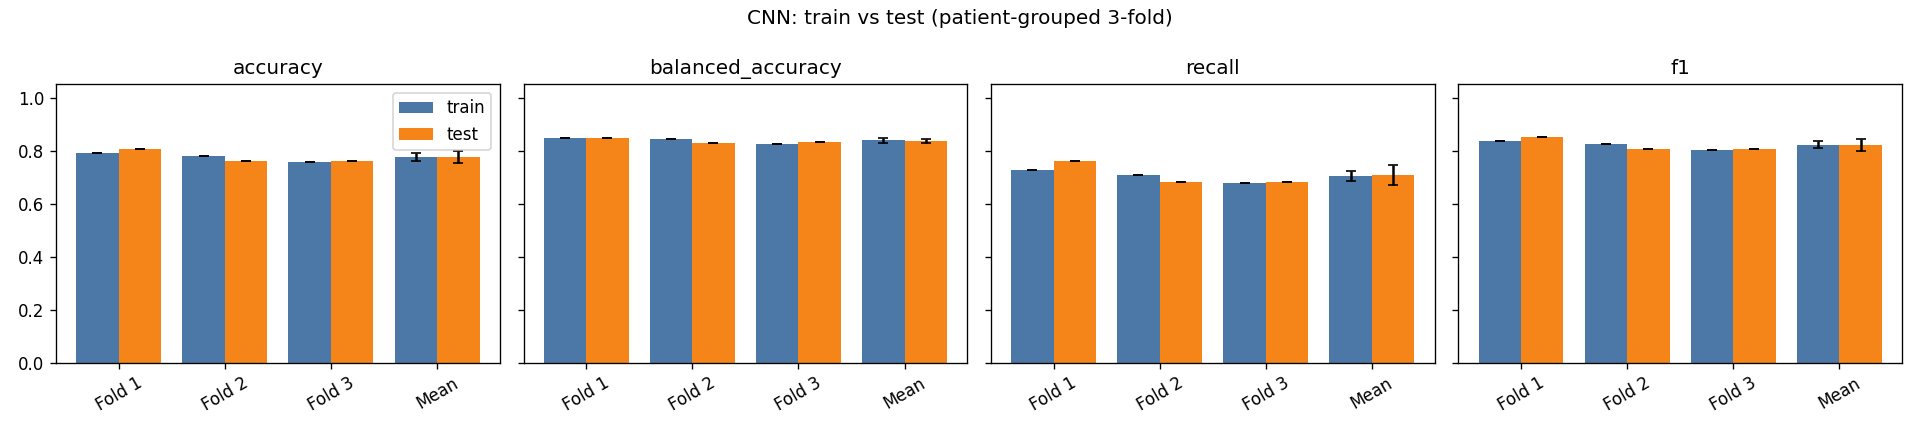

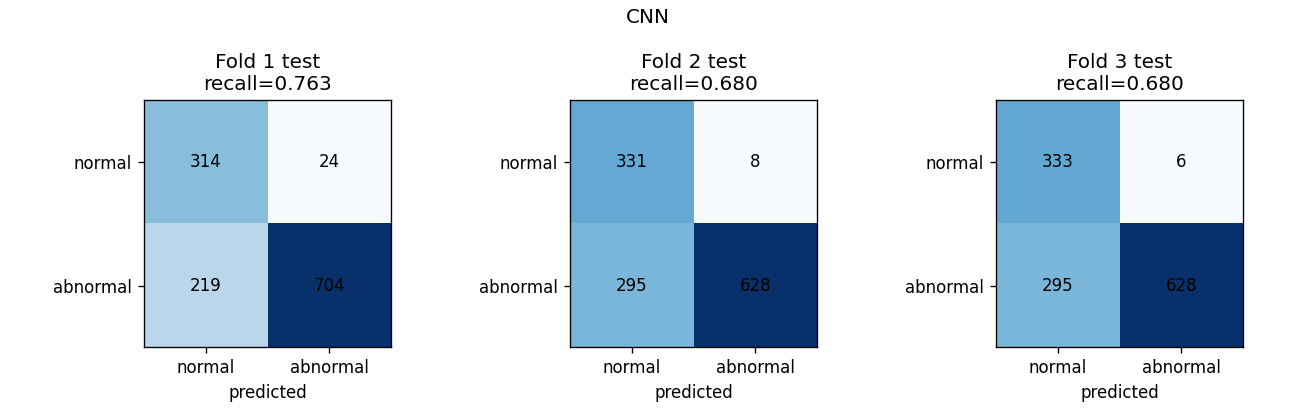

In [3]:
fig_dir = root / 'audio_engine' / 'evaluation' / 'figures' / 'cnn_custom'
display(Image(str(train_vs_test(result['folds'], result['display_name'], fig_dir / 'train_vs_test.png'))))
display(Image(str(folds_overview(result['folds'], result['display_name'], fig_dir / 'folds_overview.png'))))